# Titanic Survival Model Training

This notebook runs the training pipeline from `train_model.py` one step at a time inside the Docker training container (`quay.io/jupyter/base-notebook:python-3.13`). The trained model and its files are saved to `models/` and then copied into the serving container.

In [1]:
import train_model as tm

## 1. Load and explore the data

The data is Kaggle's Titanic `train.csv` (891 passengers), saved as `data/titanic.csv`.

In [2]:
df = tm.load_and_explore_data()

Loading Titanic dataset...
Dataset shape: (891, 12)

First few rows:
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C1

## 2. Clean the data and create new features

Missing ages and fares are filled with the median, and missing ports with the most common port. Then I add family size, traveling alone, title (from the name), age group, and fare group.

In [3]:
processed_data = tm.preprocess_data(df)
processed_data[['Age', 'Embarked', 'Fare']].isnull().sum()


Preprocessing data...
Preprocessed data shape: (891, 17)

New features created:
- FamilySize: SibSp + Parch + 1
- IsAlone: Whether passenger traveled alone
- Title: Title extracted from name
- AgeGroup: Age categories
- FareGroup: Fare categories


Age         0
Embarked    0
Fare        0
dtype: int64

## 3. Turn the text columns into numbers

In [4]:
model_data, label_encoders = tm.encode_features(processed_data)


Encoding categorical features...
Encoded Sex: ['female', 'male']
Encoded Embarked: ['C', 'Q', 'S']
Encoded Title: ['Master', 'Miss', 'Mr', 'Mrs', 'Other']
Encoded AgeGroup: ['Adult', 'Child', 'Middle', 'Senior', 'Teen']
Encoded FareGroup: ['High', 'Low', 'Medium', 'VeryHigh']


## 4. Train and evaluate the Random Forest

20% of the passengers are held out to test the model.


Training Random Forest model...
Training set size: 712
Test set size: 179

Model Accuracy: 0.8156

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.88      0.85       110
           1       0.79      0.71      0.75        69

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.82      0.81       179


Top 10 Most Important Features:
       feature  importance
1          Sex    0.281493
5         Fare    0.171489
9        Title    0.126609
2          Age    0.122544
0       Pclass    0.091813
7   FamilySize    0.051470
11   FareGroup    0.043369
3        SibSp    0.030373
6     Embarked    0.026624
10    AgeGroup    0.023146


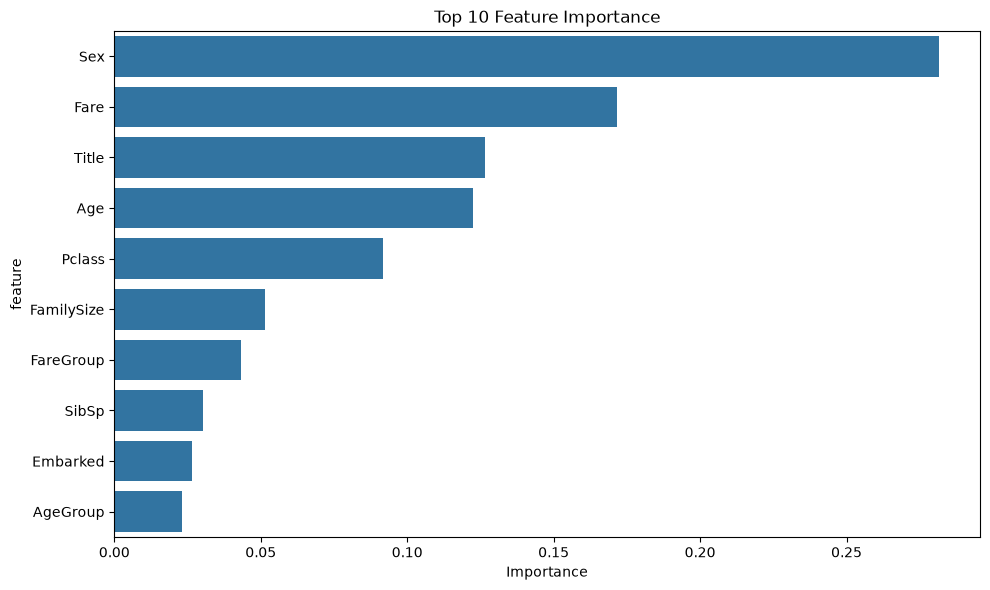

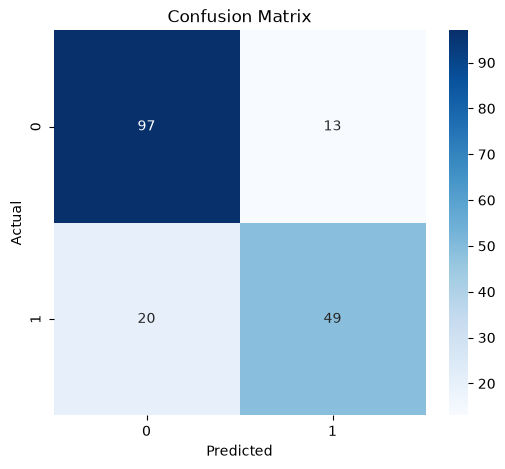

In [5]:
model, accuracy, feature_importance, feature_names = tm.train_model(model_data)

## 5. Save the model files

In [6]:
metadata = tm.save_model_artifacts(model, label_encoders, feature_names, accuracy)
print(f"Final model accuracy: {accuracy:.4f}")


Saving model artifacts...
Model saved to: models/titanic_model.joblib
Label encoders saved to: models/label_encoders.joblib
Model metadata saved to: models/model_metadata.json
Sample input saved to: models/sample_input.json

All model artifacts saved successfully!
Final model accuracy: 0.8156
